# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [3]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
# from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
df = pd.read_csv("./dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

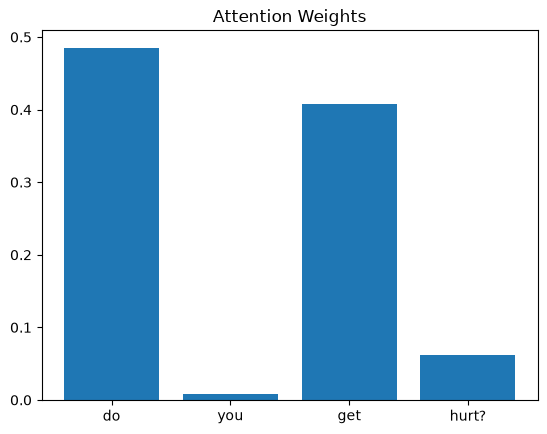

In [8]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: 'can you throw up?' | Max Word: 'up?'
Question: 'do you dream' | Max Word: 'dream'
Question: 'can you masticate?' | Max Word: 'masticate?'
Question: 'how old are you?' | Max Word: 'are'


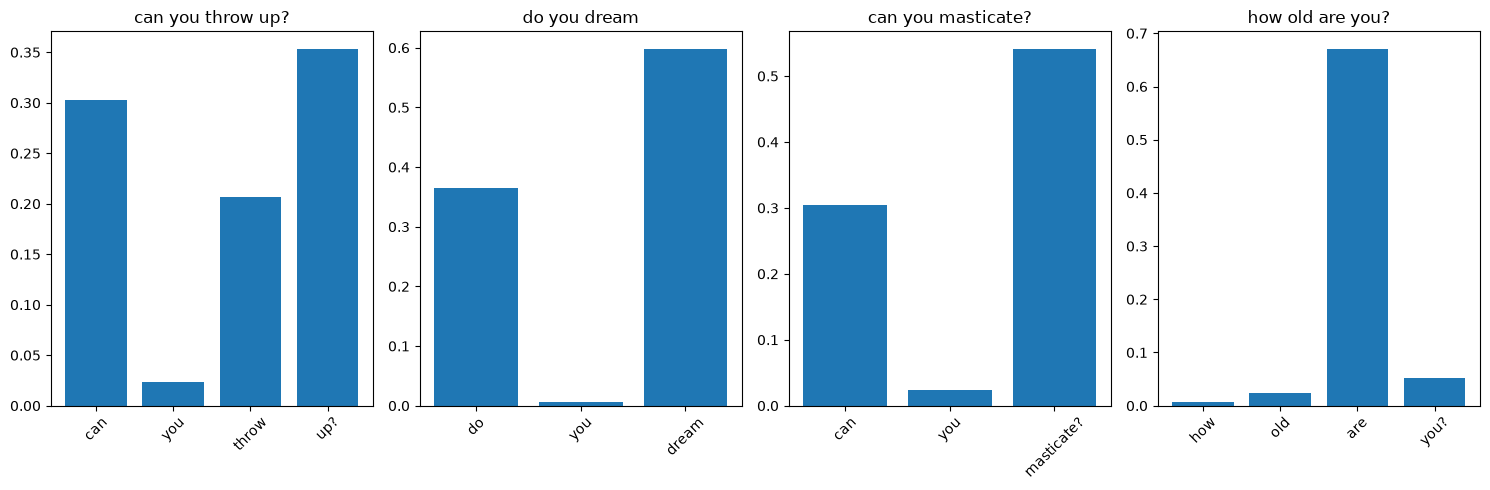

In [9]:
indices= [4, 8, 12, 24]
fig, axes = plt.subplots(1, 4, figsize= (15, 5))

for i, idx in enumerate(indices):
    question= df["question"].iloc[idx]
    words= question.lower().split()
    with torch.no_grad():
        _, weights = model(X[idx:idx + 1])
    
    weights_list= weights[0, :len(words)].tolist()
    max_word= words[weights_list.index(max(weights_list))]
    print(f"Question: '{question}' | Max Word: '{max_word}'")
    
    axes[i].bar(words, weights_list)
    axes[i].set_title(question)
    axes[i].tick_params(axis= "x", rotation= 45)

plt.tight_layout()
plt.show()

## Explanation

`While the attention weights correctly isolate the primary semantic targets in the first and third sequences ("age?" and "snack?"), the second sequence places the highest weight on the stop-word "are". When training lightweight RNN architectures on limited datasets, the attention layer does not always abstract human logic perfectly; it often learns to rely on syntactical anchors, sequence-starting tokens, or dataset-specific artifacts to minimize classification loss, rather than consistently isolating the core semantic meaning.`

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: 'want to ask any questions about me?' | Max Word: 'to'
Question: 'what do you want to know about me' | Max Word: 'know'


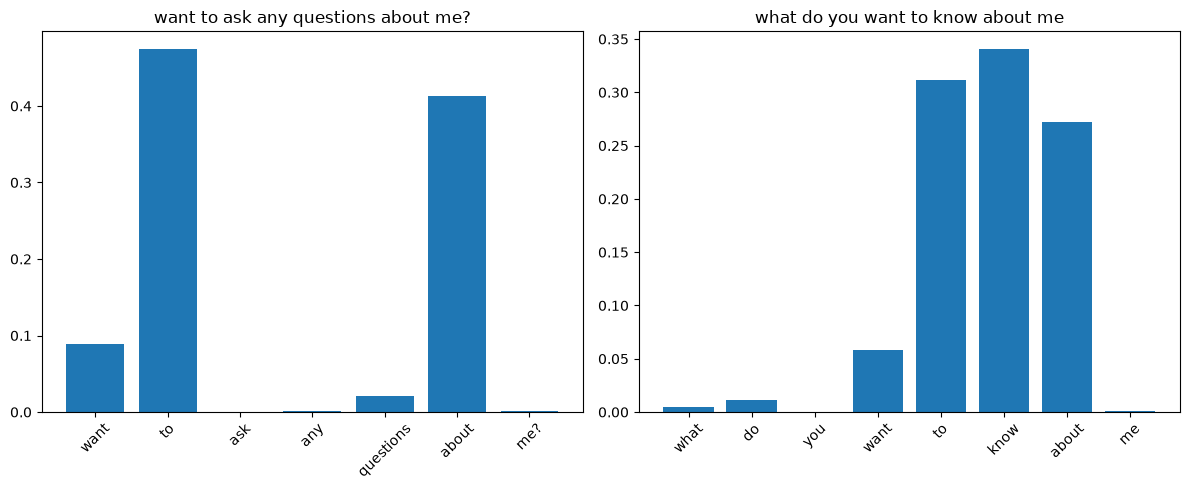

In [10]:
q1_idx= df[df["question"] == "want to ask any questions about me?"].index[0]
q2_idx= df[df["question"] == "what do you want to know about me"].index[0]

fig, axes = plt.subplots(1, 2, figsize= (12, 5))

for i, idx in enumerate([q1_idx, q2_idx]):
    question= df["question"].iloc[idx]
    words= question.lower().split()
    with torch.no_grad():
        _, weights = model(X[idx:idx + 1])
    
    weights_list= weights[0, :len(words)].tolist()
    max_word= words[weights_list.index(max(weights_list))]
    print(f"Question: '{question}' | Max Word: '{max_word}'")
    
    axes[i].bar(words, weights_list)
    axes[i].set_title(question)
    axes[i].tick_params(axis= "x", rotation= 45)

plt.tight_layout()
plt.show()

## Explanation

`Despite both questions sharing the exact same human intent, the model focuses on completely different tokens. This suggests that the attention mechanism isn't inherently understanding the abstract meaning of the sentence. Instead, the network is identifying arbitrary, discriminative token patterns (like "don't" or "one") that act as sufficient shortcuts to route the input to the correct target classification in the latent space.`